In [1]:
import pandas as pd 
import matplotlib.pyplot as plt 

In [2]:
raw = pd.read_csv("/Users/ssarahshaik/suny-project/Headcount_Enrollment_by_Student_Level_and_Student_Load_by_Institutions_of_the_State_University_of_New_York__Beginning_Fall_2011_20261010.csv")

In [3]:
raw.head()

,Year,Term,College or Institution Type,College or Institution Name,Undergraduate Full-Time,Undergraduate Part-Time,Graduate Full-Time,Graduate Part-Time
0,2025,Fall,Community Colleges,Adirondack,"1,223","1,460",NaN,NaN
1,2025,Fall,Community Colleges,Broome,"2,597","3,332",NaN,NaN
2,2025,Fall,Community Colleges,Cayuga County,747,"2,964",NaN,NaN
3,2025,Fall,Community Colleges,Clinton,353,818,NaN,NaN
4,2025,Fall,Community Colleges,Columbia-Greene,422,"1,159",NaN,NaN


In [4]:
raw.columns

Index(['Year', 'Term', 'College or Institution Type',
       'College or Institution Name', 'Undergraduate Full-Time',
       'Undergraduate Part-Time', 'Graduate Full-Time', 'Graduate Part-Time'],
      dtype='object')

In [5]:
df = raw.copy() 
df.columns = ["year", "term", "sector", "campus", "undergrad_ft", "undergrad_pt", "grad_ft", "grad_pt"]

In [6]:
raw.copy()

,Year,Term,College or Institution Type,College or Institution Name,Undergraduate Full-Time,Undergraduate Part-Time,Graduate Full-Time,Graduate Part-Time
0,2025,Fall,Community Colleges,Adirondack,"1,223","1,460",NaN,NaN
1,2025,Fall,Community Colleges,Broome,"2,597","3,332",NaN,NaN
2,2025,Fall,Community Colleges,Cayuga County,747,"2,964",NaN,NaN
3,2025,Fall,Community Colleges,Clinton,353,818,NaN,NaN
4,2025,Fall,Community Colleges,Columbia-Greene,422,"1,159",NaN,NaN
...,...,...,...,...,...,...,...,...
985,2011,Fall,Technology Colleges,Delhi,"2,607",642,NaN,NaN
986,2011,Fall,Technology Colleges,Farmingdale,"5,377","2,256",NaN,NaN
987,2011,Fall,Technology Colleges,Maritime,"1,565",96,102,60
988,2011,Fall,Technology Colleges,Morrisville,"2,861",369,NaN,NaN


In [7]:
number_cols = ["undergrad_ft", "undergrad_pt", "grad_ft", "grad_pt"]
for col in number_cols: 
    df[col] = pd.to_numeric(df[col].astype(str).str.replace(",", ""), errors = "coerce")
df[number_cols] = df[number_cols].fillna(0) #converting text into real numbers

In [8]:
campus = df.dropna(subset=["campus"]).copy()
campus["total"] = campus[number_cols].sum(axis=1)
campus.head() #drop subtotal rows to avoid double counting students

,year,term,sector,campus,undergrad_ft,undergrad_pt,grad_ft,grad_pt,total
0,2025,Fall,Community Colleges,Adirondack,1223.0,1460.0,0.0,0.0,2683.0
1,2025,Fall,Community Colleges,Broome,2597.0,3332.0,0.0,0.0,5929.0
2,2025,Fall,Community Colleges,Cayuga County,747.0,2964.0,0.0,0.0,3711.0
3,2025,Fall,Community Colleges,Clinton,353.0,818.0,0.0,0.0,1171.0
4,2025,Fall,Community Colleges,Columbia-Greene,422.0,1159.0,0.0,0.0,1581.0


campus.shape()

In [10]:
campus.shape

(915, 9)

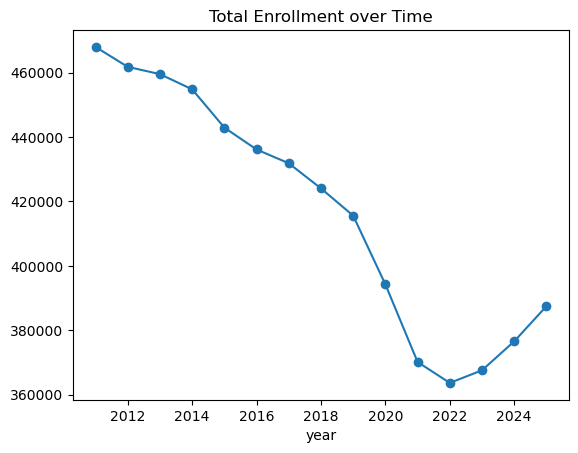

In [11]:
by_year = campus.groupby("year")["total"].sum() 
by_year.plot(marker = "o", title = "Total Enrollment over Time")
plt.show() # showing total enrollment over time

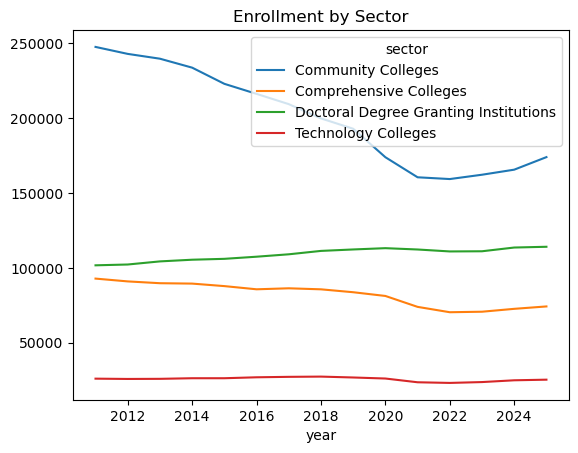

In [12]:
by_sector = campus.groupby(["year", "sector"])["total"].sum().unstack()
by_sector.plot(title = "Enrollment by Sector")
plt.show() # sectors that changed the most over time 

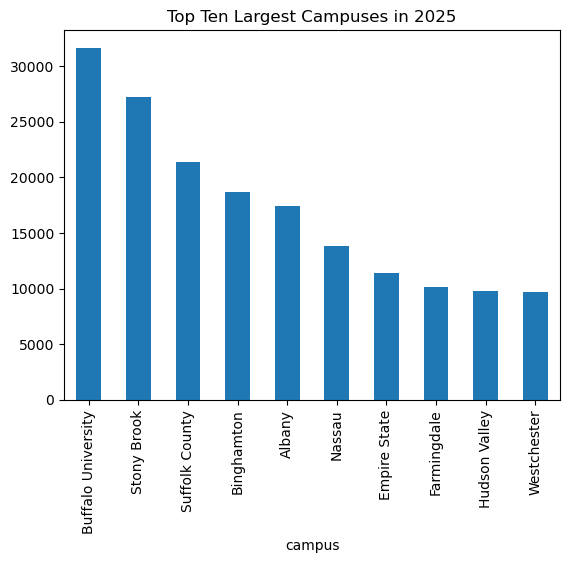

In [13]:
latest = campus[campus["year"] == 2025] 
top10 = latest.sort_values("total", ascending = False).head(10)
top10.plot.bar(x = "campus", y = "total", legend = False, title = "Top Ten Largest Campuses in 2025")
plt.show()

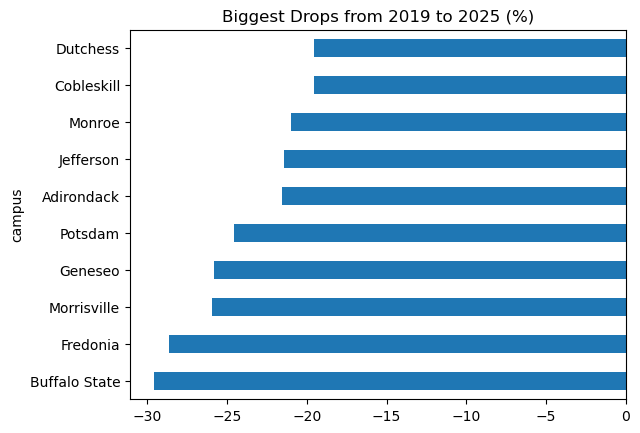

In [14]:
wide = campus.pivot(index = "year", columns = "campus", values = "total")
change = (wide.loc[2025] / wide.loc[2019] - 1) * 100 
change = change.sort_values()
change.head(10).plot.barh(title = "Biggest Drops from 2019 to 2025 (%)") 
plt.show() # biggest drops since 2019

In [15]:
(change < 0).sum()

46

Enrollment hit its lowest point in 2022 at about 364,000 students, down roughly 104,000 (22%) from 468,000 in 2011. Doctoral Degree Granting Institutions recovered best, as they grew about 12% since 2011 and are the only sector above their 2019 level. The largest campus in 2025 was Buffalo University, with about 31,700 students. It was found that 46 of the 61 campuses are still below their 2019 enrollment.